# 03 · Análisis exploratorio (EDA)

**Objetivo.** Describir a la población postulante, sus restricciones de cuidado y su situación laboral inicial, y explorar la distribución de los resultados. Con eso se fundamentan las decisiones de modelación de 04 y 05.

**Justificación.** El EDA responde preguntas que condicionan la estimación:

1. ¿A quién se puede generalizar el resultado? → perfil de la población
2. ¿Hay espacio para efectos en el margen extensivo y en el intensivo? → situación laboral inicial
3. ¿Qué forma tienen los resultados (masas en cero, asimetría, valores extremos)? → elección del estimador y pruebas de robustez
4. ¿Qué covariables predicen los resultados? → justificación del ajuste por precisión
5. ¿El uso del servicio está autoseleccionado? → necesidad de usar variables instrumentales

**Fundamento metodológico.** El análisis es **descriptivo**. Las diferencias entre grupos de oferta que aparecen aquí son estimaciones ITT sin ajuste y sin inferencia, y se formalizan en 04. Las comparaciones por **uso** ($D$) se muestran solo para documentar la selección, no como efectos.

> **En sencillo — EDA:** es "mirar los datos antes de modelarlos": tablas y gráficos para conocer a la población, detectar rarezas y decidir cómo analizar. No prueba causalidad; prepara el terreno.

### Preparación del entorno

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Rutas relativas a la raíz del repositorio
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "caso05_cuidado_infantil.dta"
PROCESSED = ROOT / "data" / "processed" / "caso05_analitico.csv"

# Roles de las variables (definidos en 00_planteamiento_teoria_cambio)
ID, CENTER = "hogar_id", "centro_id"
Z = "oferta_sorteo"            # asignación aleatoria (instrumento)
D = "uso_horario_ampliado"     # tratamiento recibido (endógeno)
BASELINE = [
    "edad_madre", "numero_hijos", "edad_menor", "educ_madre", "madre_sola",
    "traslado_min", "red_cuidado", "empleo_pre", "horas_pre", "ingreso_pre",
]
OUTCOMES = ["empleo_post", "horas_post", "ingreso_post_c", "bienestar_post"]
ALPHA, SEED = 0.05, 2026

# Estilo gráfico: oferta = azul, sin oferta = naranja; grilla recesiva
COLORS = {0: "#eb6834", 1: "#2a78d6"}
LABELS = {0: "Sin oferta (Z=0)", 1: "Con oferta (Z=1)"}
NEUTRAL = "#8a8984"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#e6e6e3", "figure.dpi": 110, "axes.titleweight": "bold",
})

In [2]:
# Base analítica generada en 01_datos_auditoria_construccion.ipynb
if not PROCESSED.exists():
    raise FileNotFoundError(
        "No existe la base analítica. Ejecute primero 01_datos_auditoria_construccion.ipynb"
    )
df = pd.read_csv(PROCESSED)
print(f"Base analítica: {df.shape[0]} filas x {df.shape[1]} columnas")

Base analítica: 1500 filas x 28 columnas


## 3.1 Perfil sociodemográfico

,mean,std,min,10%,50%,90%,max
edad_madre,29.408,5.788,18.000,21.900,29.000,37.000,45.000
educ_madre,11.599,2.951,3.000,8.000,12.000,15.000,18.000
numero_hijos,1.641,0.794,1.000,1.000,1.000,3.000,4.000
edad_menor,2.548,1.070,1.000,1.000,3.000,4.000,5.000
traslado_min,41.815,17.361,5.000,18.697,42.117,63.917,108.448


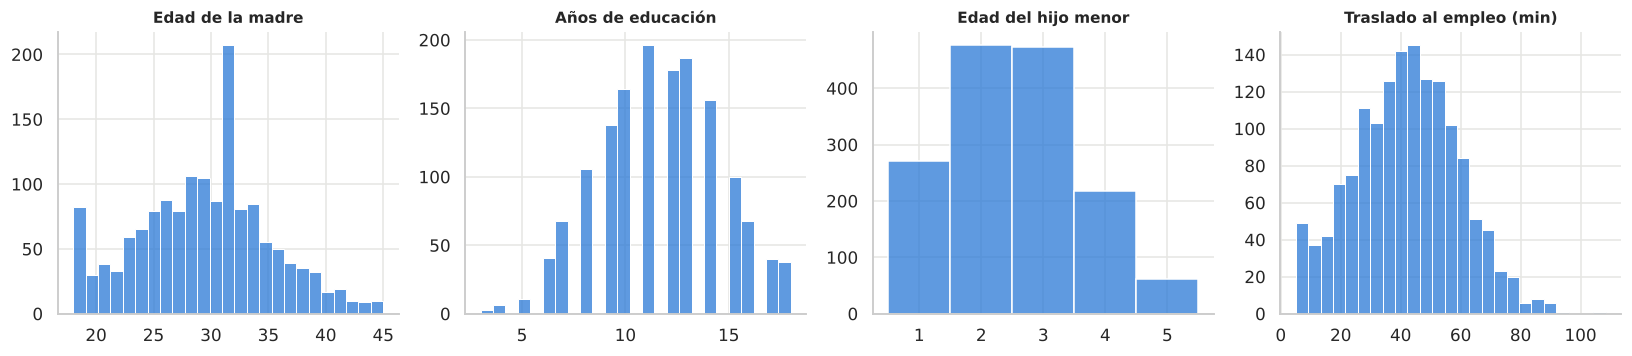

In [3]:
perfil = df[["edad_madre", "educ_madre", "numero_hijos", "edad_menor", "traslado_min"]].describe(
    percentiles=[0.1, 0.5, 0.9]).T[["mean", "std", "min", "10%", "50%", "90%", "max"]]
display(perfil)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, v, t in zip(axes, ["edad_madre", "educ_madre", "edad_menor", "traslado_min"],
                    ["Edad de la madre", "Años de educación", "Edad del hijo menor", "Traslado al empleo (min)"]):
    discreta = df[v].nunique() < 10
    sns.histplot(df[v], ax=ax, color=COLORS[1], discrete=discreta, bins=None if discreta else 25, edgecolor="white")
    ax.set_title(t, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Interpretación.** La población típica son madres jóvenes (mediana de 29 años, rango 18-45), con educación secundaria completa (mediana de 12 años), en su mayoría con 1 o 2 hijos, y con el **menor en edad preescolar** (1-5 años, mediana 3). El traslado al empleo es considerable: 42 minutos en promedio, y más de una hora para el 10 % superior. Es decir, la jornada que debe cubrir el cuidado incluye un tiempo importante de traslado. Ese es justamente el problema que busca resolver el horario ampliado. No hay valores atípicos que requieran tratamiento.

## 3.2 Restricciones de cuidado

Según la teoría de cambio, el horario ampliado debería importar más donde no hay **alternativas de cuidado**. Se cruzan las dos restricciones observadas: hogar monoparental y ausencia de red de cuidado.

In [4]:
restr = pd.crosstab(df["madre_sola"].map({0: "Con pareja", 1: "Madre sola"}),
                    df["red_cuidado"].map({0: "Sin red", 1: "Con red"}), normalize="index").mul(100)
display(restr.round(1))
print(f"Madres con restricción alta (sola y sin red): {df['restriccion_alta'].sum()} "
      f"({100 * df['restriccion_alta'].mean():.1f} %)")

# Situación laboral inicial según restricción
display(df.groupby("restriccion_alta")[["empleo_pre", "horas_pre", "traslado_min"]].mean()
        .rename(index={0: "Otras", 1: "Sola y sin red"}))

red_cuidado,Con red,Sin red
madre_sola,,
Con pareja,43.200,56.800
Madre sola,45.200,54.800


Madres con restricción alta (sola y sin red): 250 (16.7 %)


,empleo_pre,horas_pre,traslado_min
restriccion_alta,,,
Otras,0.495,16.558,42.166
Sola y sin red,0.340,11.471,40.061


**Interpretación**

- El 30 % son madres solas y el 56 % no tiene red de cuidado. Ambas restricciones son **casi independientes**: la falta de red es igual de frecuente con o sin pareja.
- El **16.7 % (250 madres)** tiene la restricción más fuerte: madre sola y sin red. En ese grupo el empleo inicial es **15 pp menor** (34 % frente a 50 %), lo que es coherente con que el cuidado sea una barrera para trabajar.
- Esto respalda la hipótesis H5. El tamaño del subgrupo (~125 por brazo) limita la precisión: según 02.8, dentro de este subgrupo solo se detectarían efectos de unas 2.5 veces el MDE global (≈ 17 pp en empleo), y para detectar una *diferencia* entre este subgrupo y el resto harían falta ≈ 19 pp (04.8).

## 3.3 Situación laboral inicial

Se separa el **margen extensivo** (trabajar o no) del **intensivo** (horas e ingreso entre quienes trabajan). Las distribuciones de horas e ingreso tienen una masa en cero que viene de las no empleadas.

,valor
Tasa de empleo (%),46.933
Horas semanales (todas),15.710
Horas semanales (empleadas),33.474
Ingreso mensual (todas),645.499
Ingreso mensual (empleadas),"1,375.354"
Ingreso por hora aprox. (empleadas),9.444


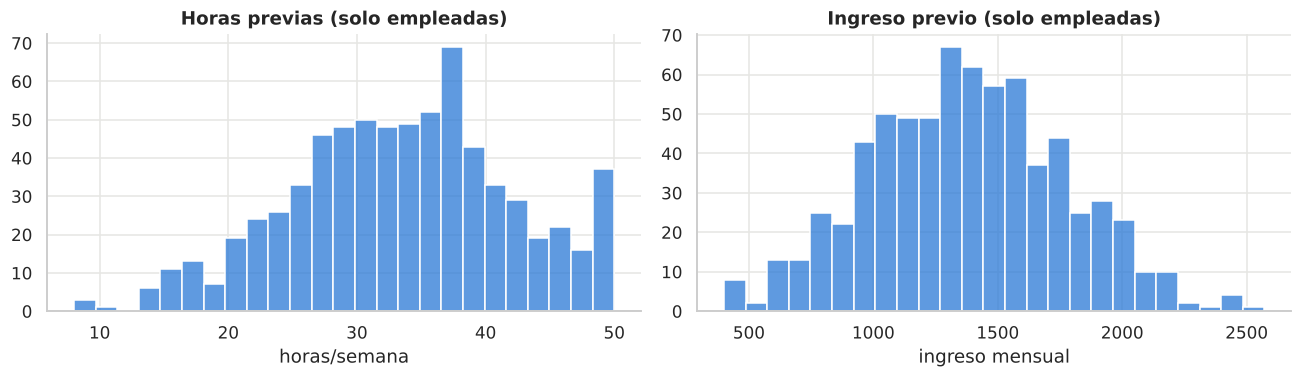

In [5]:
emp = df["empleo_pre"] == 1
inicial = pd.Series({
    "Tasa de empleo (%)": 100 * emp.mean(),
    "Horas semanales (todas)": df["horas_pre"].mean(),
    "Horas semanales (empleadas)": df.loc[emp, "horas_pre"].mean(),
    "Ingreso mensual (todas)": df["ingreso_pre"].mean(),
    "Ingreso mensual (empleadas)": df.loc[emp, "ingreso_pre"].mean(),
    "Ingreso por hora aprox. (empleadas)": (df.loc[emp, "ingreso_pre"] / (4.33 * df.loc[emp, "horas_pre"])).median(),
})
display(inicial.to_frame("valor"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
sns.histplot(df.loc[emp, "horas_pre"], ax=axes[0], color=COLORS[1], bins=25, edgecolor="white")
axes[0].set_title("Horas previas (solo empleadas)"); axes[0].set_xlabel("horas/semana")
sns.histplot(df.loc[emp, "ingreso_pre"], ax=axes[1], color=COLORS[1], bins=25, edgecolor="white")
axes[1].set_title("Ingreso previo (solo empleadas)"); axes[1].set_xlabel("ingreso mensual")
for ax in axes: ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Interpretación**

- **Margen extensivo amplio:** solo el 47 % trabajaba antes, así que hay mucho espacio para que la oferta aumente el empleo.
- **Margen intensivo:** quienes trabajaban lo hacían 33.5 horas semanales en promedio, por debajo de una jornada completa. Las horas también tienen espacio para crecer.
- El ingreso de las empleadas (≈ 1 375 u.m. mensuales, unas 9.4 u.m. por hora) tiene una distribución sin colas extremas.
- **Consecuencia:** como horas e ingreso valen 0 para el 53 % que no trabaja, el promedio poblacional mezcla los dos márgenes. Así se definen los estimandos principales (efecto total). El margen intensivo por separado requiere cotas (05).

## 3.4 Resultados según la oferta (descriptivo)

Se comparan medias antes y después por grupo de oferta. Como los grupos están balanceados en la línea base (02), la diferencia posterior es una estimación ITT **sin ajuste**.

antes  después  cambio
resultado       grupo                                    
Empleo (%)      Sin oferta (Z=0)  46.605   56.991  10.386
                Con oferta (Z=1)  47.263   66.622  19.359
Horas semanales Sin oferta (Z=0)  15.766   20.131   4.365
                Con oferta (Z=1)  15.654   25.547   9.892
Ingreso mensual Sin oferta (Z=0) 643.084  785.107 142.023
                Con oferta (Z=1) 647.921  968.725 320.804

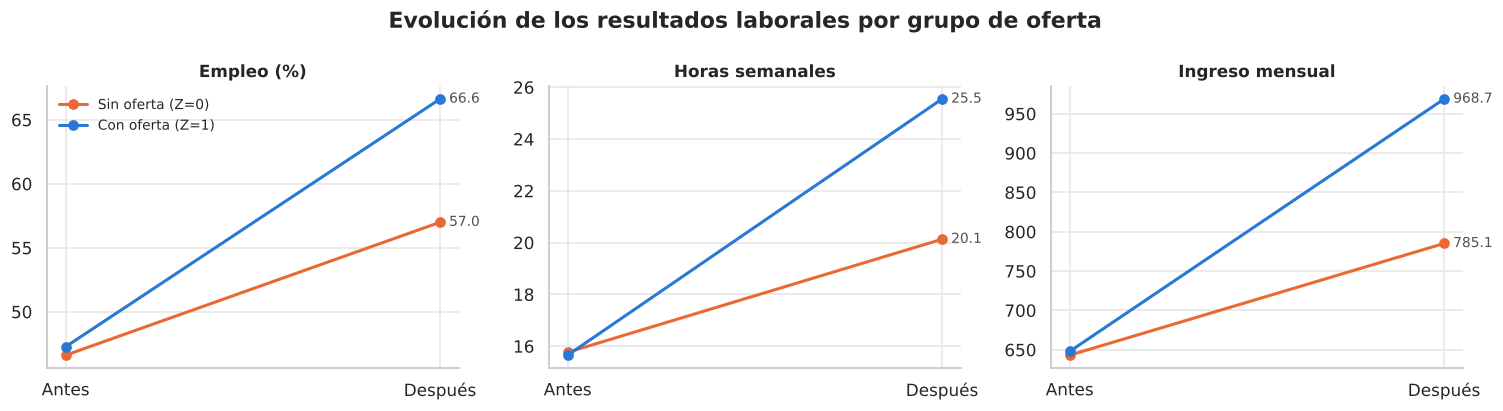

In [6]:
pares = [("empleo", "Empleo (%)", 100), ("horas", "Horas semanales", 1), ("ingreso", "Ingreso mensual", 1)]
filas = []
for v, nombre, esc in pares:
    post = "ingreso_post_c" if v == "ingreso" else f"{v}_post"
    for g in [0, 1]:
        sub = df[df[Z] == g]
        filas.append({"resultado": nombre, "grupo": LABELS[g],
                      "antes": esc * sub[f"{v}_pre"].mean(), "después": esc * sub[post].mean()})
desc = pd.DataFrame(filas)
desc["cambio"] = desc["después"] - desc["antes"]
display(desc.set_index(["resultado", "grupo"]))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (v, nombre, esc) in zip(axes, pares):
    sub = desc[desc["resultado"] == nombre]
    for g in [0, 1]:
        fila = sub[sub["grupo"] == LABELS[g]].iloc[0]
        ax.plot(["Antes", "Después"], [fila["antes"], fila["después"]], marker="o", lw=2,
                color=COLORS[g], label=LABELS[g])
        ax.annotate(f"{fila['después']:,.1f}", (1, fila["después"]), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=9, color="#52514e")
    ax.set_title(nombre, fontsize=11)
axes[0].legend(frameon=False, fontsize=9)
plt.suptitle("Evolución de los resultados laborales por grupo de oferta", fontweight="bold")
plt.tight_layout(); plt.show()

**Interpretación**

- Ambos grupos parten del mismo nivel, lo que confirma visualmente el balance de 02.
- **Ambos grupos mejoran**: el empleo del grupo sin oferta sube 10 pp. Hay una tendencia general, ya sea por el ciclo económico, porque los hijos crecen o porque estas madres buscaban activamente cuidado para trabajar. Por eso una comparación antes-después **sin grupo de control** sobrestimaría el efecto aproximadamente al doble.
- La diferencia entre grupos al final, que es el ITT sin ajustar, es de unos **9.6 pp en empleo, 5.4 horas y 184 u.m. de ingreso**. Como la línea base está balanceada, la **diferencia en diferencias** (cambio del grupo con oferta menos cambio del grupo sin oferta) da casi lo mismo: 9.0 pp, 5.5 h y 179 u.m.

## 3.5 Distribución de los resultados posteriores

Las medias pueden ocultar dónde ocurre el cambio. Las funciones de distribución acumulada (ECDF) muestran si la oferta desplaza toda la distribución o solo saca a algunas madres del cero.

> **En sencillo — cómo leer una ECDF:** para cada valor del eje horizontal, la curva indica qué proporción de madres tiene *ese valor o menos*. Si la curva de un grupo está **más abajo y a la derecha**, ese grupo tiene valores más altos. El "salto" vertical en 0 es la proporción de madres con 0 horas o 0 ingreso (las que no trabajan). La **asimetría** mide si la distribución tiene una cola larga hacia un lado. Cerca de 0, es simétrica.

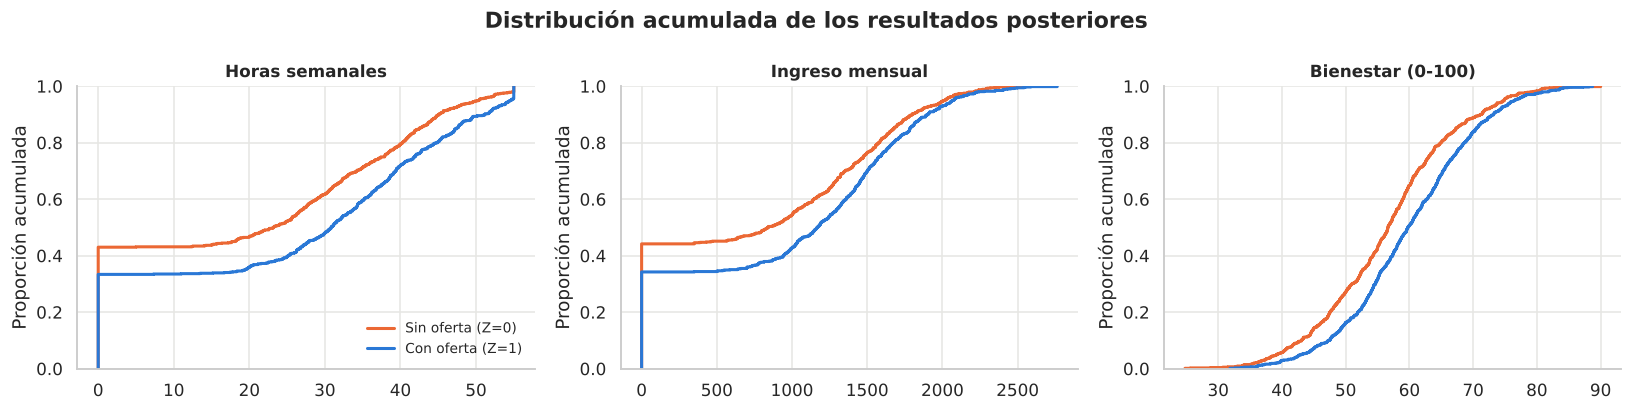

Proporción con valor 0:


,horas_post,ingreso_post_c
oferta_sorteo,,
Sin oferta (Z=0),0.430,0.430
Con oferta (Z=1),0.334,0.334


Asimetría (valores positivos): {'horas_post': np.float64(-0.06), 'ingreso_post_c': np.float64(0.07), 'bienestar_post': np.float64(0.02)}


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (v, t) in zip(axes, [("horas_post", "Horas semanales"), ("ingreso_post_c", "Ingreso mensual"),
                             ("bienestar_post", "Bienestar (0-100)")]):
    for g in [0, 1]:
        sns.ecdfplot(df.loc[df[Z] == g, v].dropna(), ax=ax, color=COLORS[g], lw=2, label=LABELS[g])
    ax.set_title(t, fontsize=11); ax.set_xlabel(""); ax.set_ylabel("Proporción acumulada")
axes[0].legend(frameon=False, fontsize=9, loc="lower right")
plt.suptitle("Distribución acumulada de los resultados posteriores", fontweight="bold")
plt.tight_layout(); plt.show()

print("Proporción con valor 0:")
display(df.groupby(Z)[["horas_post", "ingreso_post_c"]].agg(lambda s: (s == 0).mean()).rename(index=LABELS))
# Asimetría fuera de la masa en cero (con los ceros la distribución es bimodal y la asimetría no informa)
print("Asimetría (valores positivos):", {v: round(df.loc[df[v] > 0, v].skew(), 2)
                                         for v in ["horas_post", "ingreso_post_c", "bienestar_post"]})

**Interpretación**

- **Horas e ingreso:** la oferta reduce la masa en cero, de 43 % a 33 % (el margen extensivo), y la curva del grupo con oferta queda por debajo en todo el rango positivo. **Ojo:** esto ocurriría aunque la oferta *solo* sacara madres del cero, porque esas madres pasan a tener valores positivos. La ECDF no permite separar el margen extensivo del intensivo. Esa descomposición se aborda con cotas de Lee en 05.3.
- **Bienestar:** la curva del grupo con oferta está desplazada a la derecha de manera uniforme, como un desplazamiento de ubicación de unos 3-4 puntos. No hay evidencia de que la doble jornada reduzca el bienestar en alguna parte de la distribución.
- Fuera de la masa en cero, horas e ingreso son **aproximadamente simétricos** (asimetría ≈ 0) y acotados, igual que el bienestar. MCO sobre niveles es adecuado, y no hace falta usar logaritmos ni recortar extremos. Igual se prueba en 05.

## 3.6 Transiciones laborales

Se distingue a quienes **entran** al empleo de quienes **lo mantienen**. Según H5, la oferta debería actuar sobre todo en el margen de entrada.

In [8]:
trans = []
for g in [0, 1]:
    sub = df[df[Z] == g]
    trans.append({
        "grupo": LABELS[g],
        "entrada: P(empleo_post=1 | empleo_pre=0)": 100 * sub.loc[sub["empleo_pre"] == 0, "empleo_post"].mean(),
        "retención: P(empleo_post=1 | empleo_pre=1)": 100 * sub.loc[sub["empleo_pre"] == 1, "empleo_post"].mean(),
    })
trans = pd.DataFrame(trans).set_index("grupo")
trans.loc["diferencia (pp)"] = trans.iloc[1] - trans.iloc[0]
display(trans)

,entrada: P(empleo_post=1 | empleo_pre=0),retención: P(empleo_post=1 | empleo_pre=1)
grupo,,
Sin oferta (Z=0),53.367,61.143
Con oferta (Z=1),60.759,73.164
diferencia (pp),7.393,12.021


**Interpretación**

- **La entrada al empleo es alta incluso sin oferta (53 %):** muchas madres postulantes estaban por entrar al mercado laboral.
- La diferencia descriptiva es **mayor en la retención (+12 pp) que en la entrada (+7 pp)**. A primera vista esto **contradice** la parte de H5 que anticipaba efectos mayores entre quienes no trabajaban: el horario ampliado parece ayudar sobre todo a **sostener** empleos existentes. Es una comparación descriptiva; se prueba formalmente (con interacción) en 04.

## 3.7 Predictores de los resultados: justificación del ajuste por covariables

**Fundamento metodológico** [1]. En un experimento, ajustar por covariables previas no corrige sesgo (no lo hay), pero **reduce la varianza** del estimador en proporción al $R^2$ que esas covariables explican del resultado.

> **En sencillo — $R^2$ y precisión:** el $R^2$ es la parte de las diferencias entre madres (en horas, por ejemplo) que se explica con lo que ya se sabía de ellas antes del sorteo. Si las horas previas explican buena parte de las horas posteriores, al "descontar" ese componente predecible queda menos ruido, y el efecto del sorteo se ve con más nitidez. El error estándar se reduce aproximadamente en un factor $\sqrt{1-R^2}$. Se mide ese $R^2$ en el grupo sin oferta, para que no esté contaminado por el tratamiento.

,R2,reducción aprox. del EE (%)
empleo_post,0.055,2.782
horas_post,0.173,9.066
ingreso_post_c,0.198,10.453
bienestar_post,0.041,2.054


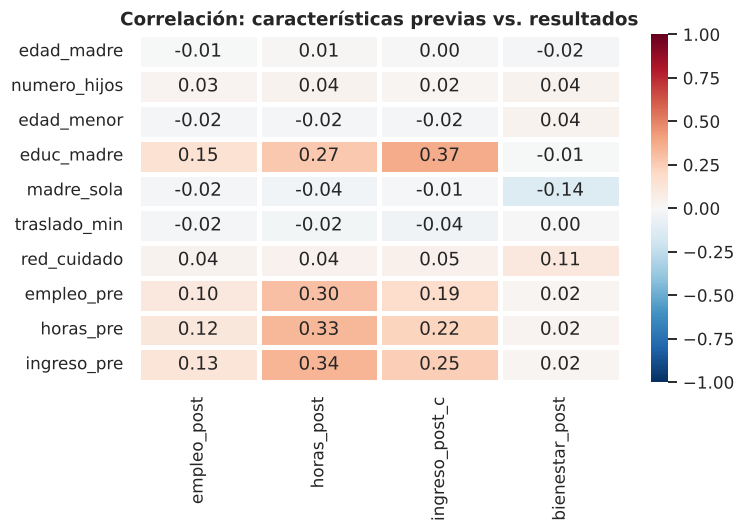

In [9]:
import statsmodels.formula.api as smf

ctrl = df[df[Z] == 0]
r2 = {}
for y in OUTCOMES:
    m = smf.ols(f"{y} ~ " + " + ".join(BASELINE) + f" + C({CENTER})", data=ctrl.dropna(subset=[y])).fit()
    r2[y] = {"R2": m.rsquared, "reducción aprox. del EE (%)": 100 * (1 - np.sqrt(1 - m.rsquared))}
display(pd.DataFrame(r2).T)

corr = df[BASELINE + OUTCOMES].corr().loc[BASELINE, OUTCOMES]
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=2, linecolor="white", ax=ax)
ax.set_title("Correlación: características previas vs. resultados")
plt.tight_layout(); plt.show()

**Interpretación**

- Las covariables previas explican el **17-20 % de la varianza** de horas e ingreso, pero solo el 4-6 % de la de empleo y bienestar.
- **Implicancia:** ajustar reduce el error estándar del ITT en alrededor de 10 % para horas e ingreso, y apenas en 2-3 % para empleo y bienestar. El ajuste no cambia la conclusión, solo mejora la precisión. Por eso la especificación sin ajuste (M1) se reporta junto a la ajustada.
- Los predictores más fuertes de horas e ingreso son sus propias líneas de base (`horas_pre`, `ingreso_pre`, `empleo_pre`). Para bienestar no hay línea base y las correlaciones son débiles.

## 3.8 Selección en el uso del servicio

**Objetivo.** Mostrar empíricamente por qué no se puede estimar el efecto del uso comparando usuarias con no usuarias.

**Fundamento metodológico.** Si el uso fuera "como aleatorio", las características previas de usuarias y no usuarias serían similares **dentro de cada grupo de oferta**. Las diferencias revelan **autoselección** (cuando las propias personas deciden si reciben el tratamiento, y quienes lo eligen son distintas de quienes no): siempre usuarias frente al resto en $Z=0$, y nunca usuarias frente al resto en $Z=1$.

grupo,Con oferta (Z=1),Sin oferta (Z=0)
variable,,
edad_madre,-0.012,0.083
edad_menor,0.034,-0.209
educ_madre,-0.104,0.097
empleo_pre,0.083,-0.147
horas_pre,0.052,-0.103
ingreso_pre,0.067,-0.131
madre_sola,0.101,0.228
numero_hijos,0.133,0.153
red_cuidado,-0.392,-0.293


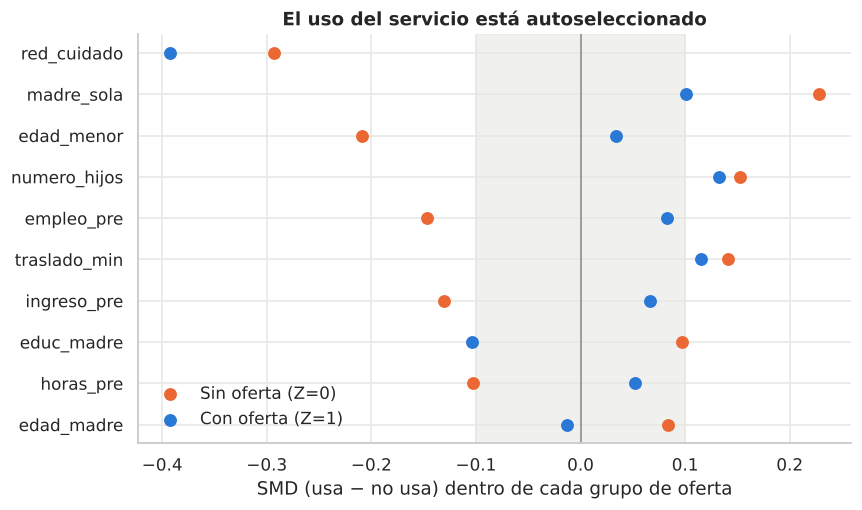

In [10]:
sel = []
for g in [0, 1]:
    sub = df[df[Z] == g]
    for v in BASELINE:
        x1, x0 = sub.loc[sub[D] == 1, v], sub.loc[sub[D] == 0, v]
        sel.append({"grupo": LABELS[g], "variable": v,
                    "smd_usa_vs_no_usa": (x1.mean() - x0.mean()) / np.sqrt((x1.var() + x0.var()) / 2)})
sel = pd.DataFrame(sel).pivot(index="variable", columns="grupo", values="smd_usa_vs_no_usa")
display(sel)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.axvspan(-0.1, 0.1, color="#e6e6e3", alpha=0.6)
ax.axvline(0, color=NEUTRAL, lw=1)
orden = sel.abs().max(axis=1).sort_values().index
for g in [0, 1]:
    ax.scatter(sel.loc[orden, LABELS[g]], orden, s=55, color=COLORS[g], label=LABELS[g], zorder=3)
ax.set_xlabel("SMD (usa − no usa) dentro de cada grupo de oferta")
ax.set_title("El uso del servicio está autoseleccionado")
ax.legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

**Interpretación**

- **Dentro de cada grupo de oferta, usuarias y no usuarias difieren sistemáticamente.** Las usuarias tienen bastante menos red de cuidado (SMD ≈ −0.3 a −0.4), son más a menudo madres solas y tienen más hijos y traslados más largos. Es decir, usa el servicio quien más lo necesita.
- En el grupo sin oferta, las siempre usuarias tenían **menos empleo e ingreso previos** (SMD ≈ −0.13 a −0.15), y su hijo menor es más pequeño (SMD −0.21).
- **Consecuencia:** una comparación por uso ($D$) mezcla el efecto del servicio con estas diferencias, y nada garantiza que ajustar por $X$ elimine las diferencias en no observables (motivación, oportunidades laborales). Esto confirma que el efecto del uso debe estimarse con **$Z$ como instrumento** (LATE), como se planteó en el DAG.

## 3.9 Síntesis, supuestos y decisiones

| Pregunta | Hallazgo | Decisión |
|---|---|---|
| ¿A quién se generaliza? | Madres jóvenes postulantes con hijos en edad preescolar | El ITT vale para postulantes. El LATE, solo para cumplidoras (perfil en 04) |
| ¿Margen de efecto? | 53 % no trabajaba; las empleadas trabajaban < 34 h | Efectos en ambos márgenes; resultados medidos en toda la población |
| ¿Hay tendencia común? | Ambos grupos mejoran (+10 pp de empleo sin oferta) | La comparación antes-después no es válida; se usa el grupo de control |
| ¿Forma de los resultados? | Masa en cero (43 %) y simetría en la parte positiva; la ECDF no separa márgenes | MCO en niveles; cotas de Lee para el margen intensivo (05) |
| ¿Covariables útiles? | $R^2$ de 17-20 % para horas e ingreso | Ajuste por covariables en la especificación principal |
| ¿Uso autoseleccionado? | Sí: según red de cuidado, empleo previo y otras | Efecto del uso solo por IV (LATE) |
| Heterogeneidad | Diferencia descriptiva mayor en retención que en entrada | Se prueba formalmente en 04 sin redefinir los subgrupos (preespecificados en 00) |

**Limitación:** todo lo anterior es descriptivo y sin inferencia. Las magnitudes formales con sus intervalos están en 04.

## Referencias

1. Athey, S. e Imbens, G. W. (2017). The econometrics of randomized experiments. En A. V. Banerjee y E. Duflo (eds.), *Handbook of Economic Field Experiments* (vol. 1, pp. 73-140). North-Holland. https://doi.org/10.1016/bs.hefe.2016.10.003